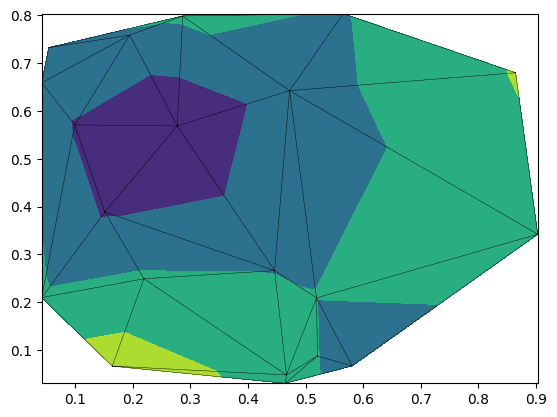

In [10]:
import numpy as np, matplotlib.pyplot as plt
import matplotlib.tri as tri

x, y = np.random.rand(2, 20)
z = np.sin(6*x) * np.cos(6*y)          # 在不規則點上的觀測值
t = tri.Triangulation(x, y)             # Delaunay 剖分
plt.tricontourf(t, z, levels=3)        # 直接畫等高線填色
plt.triplot(t, lw=0.3, color='k')       # 疊上三角網格看看結構
plt.show()

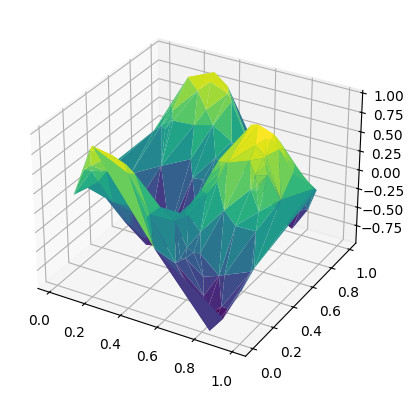

In [4]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot_trisurf(x, y, z, cmap='viridis')   # 內部對 (x, y) 做 Delaunay
plt.show()


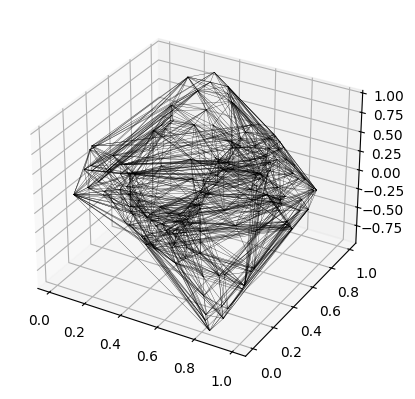

In [5]:

from scipy.spatial import Delaunay
from itertools import combinations

pts = np.column_stack([x, y, z])        # 注意：rand(3,200) 要轉成 (200, 3)
d = Delaunay(pts)                        # d.simplices 形狀為 (n, 4)，每列一個四面體
edges = {tuple(sorted(e)) for s in d.simplices for e in combinations(s, 2)}

ax = plt.figure().add_subplot(projection='3d')
for i, j in edges:
    ax.plot(*pts[[i, j]].T, lw=0.2, color='k')
plt.show()

       資料          方法                                               每箱點數                                                                    箱界  平滑誤差 RMSE  平滑後不同值個數
  A. 平滑資料 equal-width   [70, 223, 248, 225, 242, 254, 242, 256, 199, 41]     [8.1, 10.5, 12.9, 15.3, 17.7, 20.1, 22.6, 25.0, 27.4, 29.8, 32.2]       0.67        10
  A. 平滑資料 equal-depth [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]     [8.1, 11.8, 14.1, 15.9, 18.0, 20.0, 21.9, 24.0, 26.0, 27.8, 32.2]       0.63        10
B. 分歧大的資料 equal-width               [1819, 147, 19, 0, 0, 0, 3, 3, 5, 4] [1.0, 17.0, 32.7, 48.5, 64.3, 80.1, 95.9, 111.6, 127.4, 143.2, 159.0]       3.65         7
B. 分歧大的資料 equal-depth [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]          [1.2, 3.4, 4.5, 5.5, 6.4, 7.5, 8.8, 10.3, 12.4, 16.3, 159.0]       9.42        10


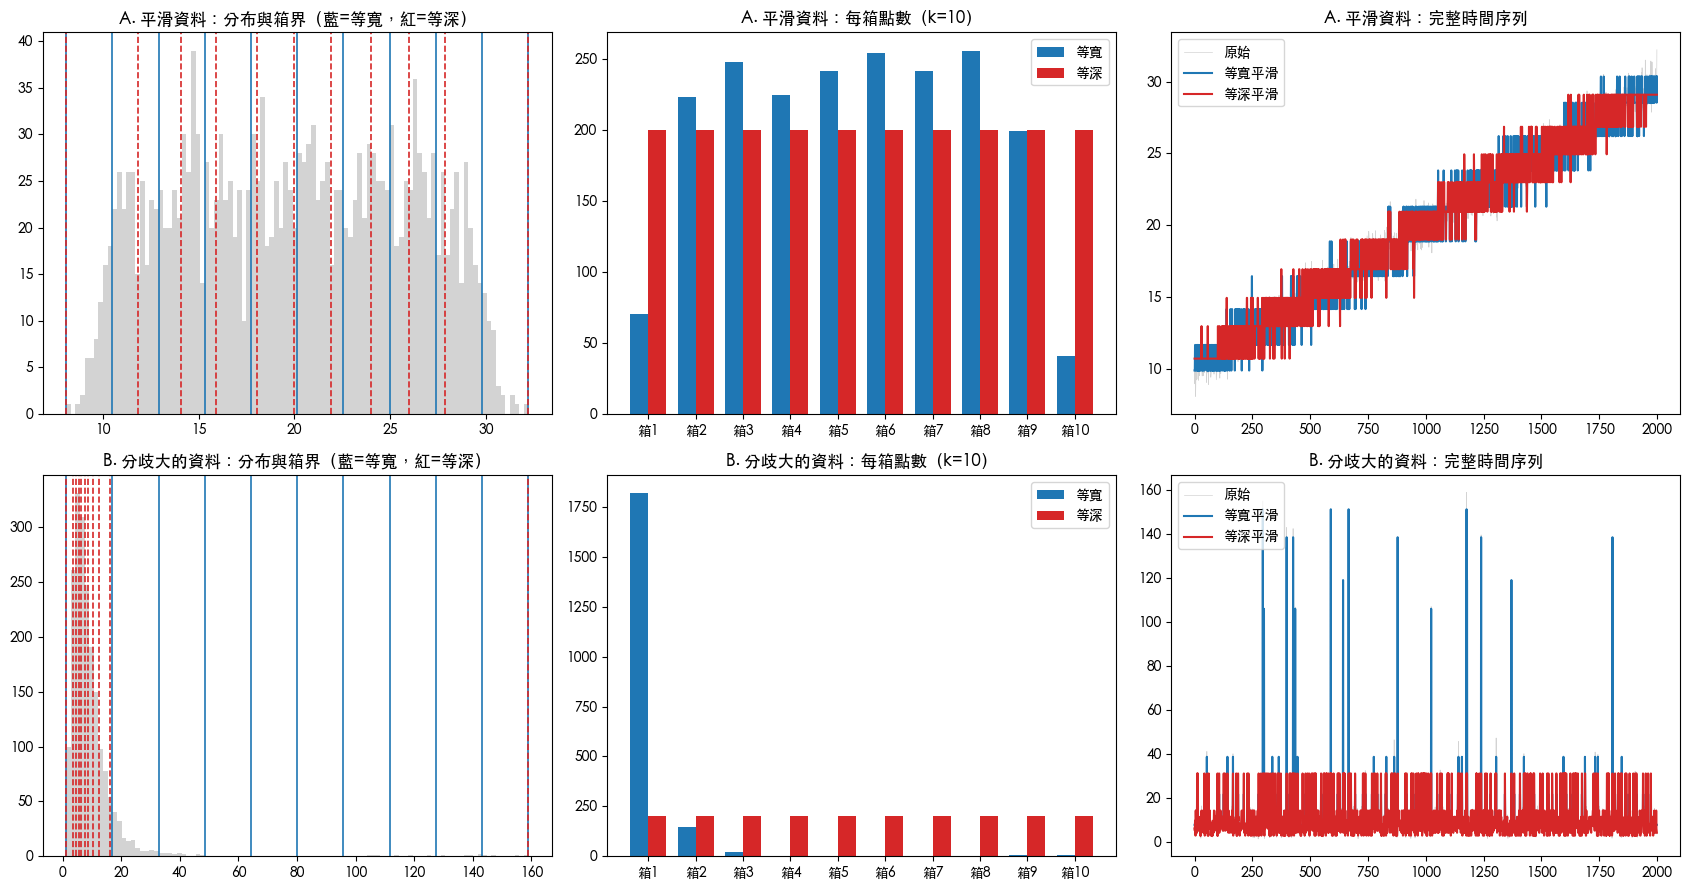

In [12]:
"""
等寬 vs 等深分箱平滑：在「平滑資料」與「分歧大的資料」上的比較
等寬 → pandas.cut      等深 → pandas.qcut
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字型：依序嘗試常見字型（macOS / Windows / Linux），都沒有就維持預設
from matplotlib import font_manager
for f in ["/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"]:
    try:
        font_manager.fontManager.addfont(f)
    except Exception:
        pass
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "PingFang TC", "Microsoft JhengHei",
                                   "Heiti TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
rng = np.random.default_rng(42)
n = 2000
t = np.arange(n)

# ---------- 模擬資料 ----------
# A. 平滑資料：線性趨勢 + 小雜訊 → 數值分布大致均勻
smooth = 10 + 0.01 * t + rng.normal(0, 1, n)

# B. 分歧大的資料：右偏（對數常態）+ 少數極端尖峰
skewed = rng.lognormal(mean=2, sigma=0.6, size=n)
spikes = rng.choice(n, size=15, replace=False)
skewed[spikes] += rng.uniform(80, 150, size=15)

datasets = {"A. 平滑資料": smooth, "B. 分歧大的資料": skewed}


def bin_smooth(x, k, method):
    """回傳 (by-means 平滑後的序列, 每箱點數, 箱界)"""
    s = pd.Series(x)
    if method == "equal-width":
        labels, edges = pd.cut(s, bins=k, labels=False, retbins=True)
    else:  # equal-depth
        labels, edges = pd.qcut(s, q=k, labels=False, retbins=True)
    smoothed = s.groupby(labels).transform("mean").to_numpy()
    counts = labels.value_counts().reindex(range(k), fill_value=0).to_numpy()
    return smoothed, counts, edges


K = 10
rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for r, (name, x) in enumerate(datasets.items()):
    res = {m: bin_smooth(x, K, m) for m in ["equal-width", "equal-depth"]}

    # (1) 直方圖 + 兩種箱界
    ax = axes[r, 0]
    ax.hist(x, bins=100, color="lightgray")
    for e in res["equal-width"][2]:
        ax.axvline(e, color="tab:blue", ls="-", lw=1.2)
    for e in res["equal-depth"][2]:
        ax.axvline(e, color="tab:red", ls="--", lw=1.2)
    ax.set_title(f"{name}：分布與箱界（藍=等寬，紅=等深）")

    # (2) 每箱點數
    ax = axes[r, 1]
    w = 0.38
    ax.bar(np.arange(K) - w / 2, res["equal-width"][1], w, label="等寬", color="tab:blue")
    ax.bar(np.arange(K) + w / 2, res["equal-depth"][1], w, label="等深", color="tab:red")
    ax.set_xticks(range(K), [f"箱{i+1}" for i in range(K)])
    ax.set_title(f"{name}：每箱點數（k={K}）")
    ax.legend()

    # (3) 完整時間序列 + 平滑結果
    ax = axes[r, 2]
    sl = slice(None)
    ax.plot(t[sl], x[sl], color="lightgray", lw=0.5, label="原始")
    ax.plot(t[sl], res["equal-width"][0][sl], color="tab:blue", lw=1.5, label="等寬平滑")
    ax.plot(t[sl], res["equal-depth"][0][sl], color="tab:red", lw=1.5, label="等深平滑")
    ax.set_title(f"{name}：完整時間序列")
    ax.legend(loc="upper left")

    for m, (sm, cnt, edges) in res.items():
        rows.append({
            "資料": name, "方法": m,
            "每箱點數": cnt.tolist(),
            "箱界": np.round(edges, 1).tolist(),
            "平滑誤差 RMSE": round(float(np.sqrt(np.mean((x - sm) ** 2))), 2),
            "平滑後不同值個數": int(np.unique(np.round(sm, 6)).size),
        })

plt.tight_layout()
plt.savefig("binning_compare.png", dpi=120)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
print(pd.DataFrame(rows).to_string(index=False))